
# ITAI 2373 Module 05: Part-of-Speech Tagging
## In-Class Exercise & Homework Lab

Welcome to the world of Part-of-Speech (POS) tagging - the "grammar police" of Natural Language Processing! 🚔📝

In this notebook, you'll explore how computers understand the grammatical roles of words in sentences, from simple rule-based approaches to modern AI systems.

### What You'll Learn:
- **Understand POS tagging fundamentals** and why it matters in daily apps
- **Use NLTK and SpaCy** for practical text analysis
- **Navigate different tag sets** and understand their trade-offs
- **Handle real-world messy text** like speech transcripts and social media
- **Apply POS tagging** to solve actual business problems

### Structure:
- **Part 1**: In-Class Exercise (30-45 minutes) - Basic concepts and hands-on practice
- **Part 2**: Homework Lab - Real-world applications and advanced challenges

---

*💡 **Pro Tip**: POS tagging is everywhere! It helps search engines understand "Apple stock" vs "apple pie", helps Siri understand your commands, and powers autocorrect on your phone.*



## 🛠️ Setup and Installation

Let's get our tools ready! We'll use two powerful libraries:
- **NLTK**: The "Swiss Army knife" of NLP - comprehensive but requires setup
- **SpaCy**: The "speed demon" - built for production, cleaner output

Run the cells below to install and set up everything we need.


In [ ]:

# Install required libraries (run this first!)
!pip install nltk spacy matplotlib seaborn pandas
!python -m spacy download en_core_web_sm

print("✅ Installation complete!")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 91.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ Installation complete!


In [ ]:

# Import all the libraries we'll need
import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Download NLTK data (this might take a moment)
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('universal_tagset')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

# Load SpaCy model
nlp = spacy.load('en_core_web_sm')

print("🎉 All libraries loaded successfully!")
print("📚 NLTK version:", nltk.__version__)
print("🚀 SpaCy version:", spacy.__version__)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package universal_tagset to /root/nltk_data...
[nltk_data]   Unzipping taggers/universal_tagset.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


🎉 All libraries loaded successfully!
📚 NLTK version: 3.9.1
🚀 SpaCy version: 3.8.16



---
# 🎯 PART 1: IN-CLASS EXERCISE (30-45 minutes)

Welcome to the hands-on portion! We'll start with the basics and build up your understanding step by step.

## Learning Goals for Part 1:
1. Understand what POS tagging does
2. Use NLTK and SpaCy for basic tagging
3. Interpret and compare different tag outputs
4. Explore word ambiguity with real examples
5. Compare different tagging approaches



## 🔍 Activity 1: Your First POS Tags (10 minutes)

Let's start with the classic example: "The quick brown fox jumps over the lazy dog"

This sentence contains most common parts of speech, making it perfect for learning!


In [ ]:

# Let's start with a classic example
sentence = "The quick brown fox jumps over the lazy dog"

import nltk
nltk.download('punkt_tab')
# TODO: Use NLTK to tokenize and tag the sentence
# Hint: Use nltk.word_tokenize() and nltk.pos_tag()
tokens = nltk.word_tokenize(sentence)
pos_tags = nltk.pos_tag(tokens)

print("Original sentence:", sentence)
print("\nTokens:", tokens)
print("\nPOS Tags:")
for word, tag in pos_tags:
    print(f"  {word:8} -> {tag}")


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Original sentence: The quick brown fox jumps over the lazy dog

Tokens: ['The', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']

POS Tags:
  The      -> DT
  quick    -> JJ
  brown    -> NN
  fox      -> NN
  jumps    -> VBZ
  over     -> IN
  the      -> DT
  lazy     -> JJ
  dog      -> NN


### 🤔 Quick Questions:
1. What does 'DT' mean? What about 'JJ'?

DT means determiner, and JJ means adjective.

2. Why do you think 'brown' and 'lazy' have the same grammatical role?

Both words describe nouns, so they are adjectives. However, NLTK incorrectly tagged "brown" as a noun and correctly tagged "lazy" as an adjective.

3. Can you guess what 'VBZ' represents?

VBZ means a third-person singular verb in the present tense.

*Hint: Think about the grammatical role each word plays in the sentence!*


## 🚀 Activity 2: SpaCy vs NLTK Showdown (10 minutes)

Now let's see how SpaCy handles the same sentence. SpaCy uses cleaner, more intuitive tag names.


In [ ]:

# TODO: Process the same sentence with SpaCy
# Hint: Use nlp(sentence) and access .text and .pos_ attributes
doc = nlp(sentence)

print("SpaCy POS Tags:")
for token in doc:
    print(f"  {token.text:8} -> {token.pos_:6} ({token.tag_})")

print("\n" + "="*50)
print("COMPARISON:")
print("="*50)

# Let's compare side by side
nltk_tags = nltk.pos_tag(nltk.word_tokenize(sentence))
spacy_doc = nlp(sentence)

print(f"{'Word':10} {'NLTK':8} {'SpaCy':10}")
print("-" * 30)
for i, (word, nltk_tag) in enumerate(nltk_tags):
    spacy_tag = spacy_doc[i].pos_
    print(f"{word:10} {nltk_tag:8} {spacy_tag:10}")


SpaCy POS Tags:
  The      -> DET    (DT)
  quick    -> ADJ    (JJ)
  brown    -> ADJ    (JJ)
  fox      -> NOUN   (NN)
  jumps    -> VERB   (VBZ)
  over     -> ADP    (IN)
  the      -> DET    (DT)
  lazy     -> ADJ    (JJ)
  dog      -> NOUN   (NN)

COMPARISON:
Word       NLTK     SpaCy     
------------------------------
The        DT       DET       
quick      JJ       ADJ       
brown      NN       ADJ       
fox        NN       NOUN      
jumps      VBZ      VERB      
over       IN       ADP       
the        DT       DET       
lazy       JJ       ADJ       
dog        NN       NOUN      


### 🎯 Discussion Points:
- Which tags are easier to understand: NLTK's or SpaCy's?

SpaCy's tags are easier for me to understand because it uses clear labels such as NOUN, VERB, and ADJ. NLTK uses shorter codes that may require a reference table.

- Do you notice any differences in how they tag the same words?

Yes. NLTK gives more detail for the word "jumps" by using VBZ, while SpaCy simply labels it as a verb. NLTK also tagged "brown" as a noun, but SpaCy correctly tagged it as an adjective.

- Which system would you prefer for a beginner? Why?

I would choose SpaCy for a beginner because its tags are easier to read and understand.


## 🎭 Activity 3: The Ambiguity Challenge (15 minutes)

Here's where things get interesting! Many words can be different parts of speech depending on context. Let's explore this with some tricky examples.


In [ ]:

# Ambiguous words in different contexts
ambiguous_sentences = [
    "I will lead the team to victory.",           # lead = verb
    "The lead pipe is heavy.",                    # lead = noun (metal)
    "She took the lead in the race.",            # lead = noun (position)
    "The bank approved my loan.",                # bank = noun (financial)
    "We sat by the river bank.",                 # bank = noun (shore)
    "I bank with Chase.",                        # bank = verb
]

print("🎭 AMBIGUITY EXPLORATION")
print("=" * 40)

for sentence in ambiguous_sentences:
    print(f"\nSentence: {sentence}")

    # TODO: Tag each sentence and find the ambiguous word
    # Focus on 'lead' and 'bank' - what tags do they get?
    tokens = nltk.word_tokenize(sentence)
    tags = nltk.pos_tag(tokens)

    # Find and highlight the key word
    for word, tag in tags:
        if word.lower() in ['lead', 'bank']:
            print(f"  🎯 '{word}' is tagged as: {tag}")


🎭 AMBIGUITY EXPLORATION

Sentence: I will lead the team to victory.
  🎯 'lead' is tagged as: VB

Sentence: The lead pipe is heavy.
  🎯 'lead' is tagged as: NN

Sentence: She took the lead in the race.
  🎯 'lead' is tagged as: NN

Sentence: The bank approved my loan.
  🎯 'bank' is tagged as: NN

Sentence: We sat by the river bank.
  🎯 'bank' is tagged as: NN

Sentence: I bank with Chase.
  🎯 'bank' is tagged as: NN


### 🧠 Think About It:
1. How does the computer know the difference between "lead" (metal) and "lead" (guide)?

The computer looks at the words around "lead" and how the sentence is structured. This context helps it decide whether the word is a noun or a verb.

2. What clues in the sentence help determine the correct part of speech?

The words around it, the word order, and its position in the sentence all provide useful clues.

3. Can you think of other words that change meaning based on context?

The word "light" is one example. In "Turn on the light," light is a noun. In "Light the candle," light is a verb.

**Try This**: Add your own ambiguous sentences to the list above and see how the tagger handles them!


## 📊 Activity 4: Tag Set Showdown (10 minutes)

NLTK can use different tag sets. Let's compare the detailed Penn Treebank tags (~45 tags) with the simpler Universal Dependencies tags (~17 tags).


In [ ]:

# Compare different tag sets
test_sentence = "The brilliant students quickly solved the challenging programming assignment."

# TODO: Get tags using both Penn Treebank and Universal tagsets
# Hint: Use tagset='universal' parameter for universal tags
tokens = nltk.word_tokenize(test_sentence)
penn_tags = nltk.pos_tag(tokens)
universal_tags = nltk.pos_tag(tokens, tagset='universal')

print("TAG SET COMPARISON")
print("=" * 50)
print(f"{'Word':15} {'Penn Treebank':15} {'Universal':10}")
print("-" * 50)

# TODO: Print comparison table
# Hint: Zip the two tag lists together
for (word, penn_tag), (_, univ_tag) in zip(penn_tags, universal_tags):
    print(f"{word:15} {penn_tag:15} {univ_tag:10}")

# Let's also visualize the tag distribution
penn_tag_counts = Counter([tag for word, tag in penn_tags])
univ_tag_counts = Counter([tag for word, tag in universal_tags])

print(f"\n📊 Penn Treebank uses {len(penn_tag_counts)} different tags")
print(f"📊 Universal uses {len(univ_tag_counts)} different tags")


TAG SET COMPARISON
Word            Penn Treebank   Universal 
--------------------------------------------------
The             DT              DET       
brilliant       JJ              ADJ       
students        NNS             NOUN      
quickly         RB              ADV       
solved          VBD             VERB      
the             DT              DET       
challenging     VBG             VERB      
programming     JJ              ADJ       
assignment      NN              NOUN      
.               .               .         

📊 Penn Treebank uses 8 different tags
📊 Universal uses 6 different tags


### 🤔 Reflection Questions:
1. Which tag set is more detailed? Which is simpler?

Penn Treebank is more detailed because it gives more information about each word. The Universal tag set is simpler because it uses broader categories.

2. When might you want detailed tags versus simple tags?

Detailed tags can be useful for grammar checking because information such as tense and word form matters. Simple tags work well when we only need basic categories such as noun, verb, and adjective.

3. If you were building a search engine, which would you choose? Why?

I would choose Universal tags because the broader categories are usually enough to understand a search query, and they are easier to work with.
---


---
# 🎓 End of Part 1: In-Class Exercise

Great work! You've learned the fundamentals of POS tagging and gotten hands-on experience with both NLTK and SpaCy.

## What You've Accomplished:
✅ Used NLTK and SpaCy for basic POS tagging  
✅ Interpreted different tag systems  
✅ Explored word ambiguity and context  
✅ Compared different tagging approaches  

## 🏠 Ready for Part 2?
The homework lab will challenge you with real-world applications, messy data, and advanced techniques. You'll analyze customer service transcripts, handle informal language, and benchmark different taggers.

**Take a break, then dive into Part 2 when you're ready!**

---



# 🏠 PART 2: HOMEWORK LAB
## Real-World POS Tagging Challenges

Welcome to the advanced section! Here you'll tackle the messy, complex world of real text data. This is where POS tagging gets interesting (and challenging)!

## Learning Goals for Part 2:
1. Process real-world, messy text data
2. Handle speech transcripts and informal language
3. Analyze customer service scenarios
4. Benchmark and compare different taggers
5. Understand limitations and edge cases

## 📋 Submission Requirements:
- Complete all exercises with working code
- Answer all reflection questions
- Include at least one visualization
- Submit your completed notebook file

---



## 🌍 Lab Exercise 1: Messy Text Challenge (25 minutes)

Real-world text is nothing like textbook examples! Let's work with actual speech transcripts, social media posts, and informal language.


In [ ]:

# Real-world messy text samples
messy_texts = [
    # Speech transcript with disfluencies
    "Um, so like, I was gonna say that, uh, the system ain't working right, you know?",

    # Social media style
    "OMG this app is sooo buggy rn 😤 cant even login smh",

    # Customer service transcript
    "Yeah hi um I'm calling because my internet's been down since like yesterday and I've tried unplugging the router thingy but it's still not working",

    # Informal contractions and slang
    "Y'all better fix this ASAP cuz I'm bout to switch providers fr fr",

    # Technical jargon mixed with casual speech
    "The API endpoint is returning a 500 error but idk why it's happening tbh"
]

print("🔍 PROCESSING MESSY TEXT")
print("=" * 60)

# TODO: Process each messy text sample
# 1. Use both NLTK and SpaCy
# 2. Count how many words each tagger fails to recognize properly
# 3. Identify problematic words (slang, contractions, etc.)

for i, text in enumerate(messy_texts, 1):
    print(f"\n📝 Sample {i}: {text}")
    print("-" * 40)

    # NLTK processing
    nltk_tokens = nltk.word_tokenize(text)
    nltk_tags = nltk.pos_tag(nltk_tokens)

    # TODO: SpaCy processing
    spacy_doc = nlp(text)

    # TODO: Find problematic words (tagged as 'X' or unknown)
    problematic_nltk = [w for w, t in nltk_tags if t in ['FW', 'SYM', 'X', '$']]
    problematic_spacy = [token.text for token in spacy_doc if token.pos_ in ['X', 'SYM']]

    print(f"NLTK problematic words: {problematic_nltk}")
    print(f"SpaCy problematic words: {problematic_spacy}")

    # TODO: Calculate success rate
    nltk_success_rate = (len(nltk_tags) - len(problematic_nltk)) / len(nltk_tags)
    spacy_success_rate = (len(spacy_doc) - len(problematic_spacy)) / len(spacy_doc)

    print(f"NLTK success rate: {nltk_success_rate:.1%}")
    print(f"SpaCy success rate: {spacy_success_rate:.1%}")


🔍 PROCESSING MESSY TEXT

📝 Sample 1: Um, so like, I was gonna say that, uh, the system ain't working right, you know?
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
SpaCy success rate: 100.0%

📝 Sample 2: OMG this app is sooo buggy rn 😤 cant even login smh
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
SpaCy success rate: 100.0%

📝 Sample 3: Yeah hi um I'm calling because my internet's been down since like yesterday and I've tried unplugging the router thingy but it's still not working
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
SpaCy success rate: 100.0%

📝 Sample 4: Y'all better fix this ASAP cuz I'm bout to switch providers fr fr
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
SpaCy suc

### 🎯 Analysis Questions:
1. Which tagger handles informal language better?

Based on the output, both taggers performed equally because they received a 100% success rate for every sample. However, this score only means that the code did not find the selected problematic tags. It does not prove that every word was tagged correctly.

2. What types of words cause the most problems?

The messy-text output did not identify any problematic words. However, the edge-case analysis showed that symbols and emojis can cause problems. Slang, abbreviations, missing apostrophes, and unusual spellings may also be difficult to tag correctly.

3. How might you preprocess text to improve tagging accuracy?

We could expand slang and contractions, correct common spelling mistakes, and change emojis into words. For example, "rn" could be changed to "right now."

4. What are the implications for real-world applications?

If a chatbot or customer-support system tags important words incorrectly, it may misunderstand what the customer needs and give the wrong response. A search engine may also return less relevant results.



## 📞 Lab Exercise 2: Customer Service Analysis Case Study (30 minutes)

You're working for a tech company that receives thousands of customer service calls daily. Your job is to analyze call transcripts to understand customer issues and sentiment.

**Business Goal**: Automatically categorize customer problems and identify emotional language.


In [ ]:

# Simulated customer service call transcripts
customer_transcripts = [
    {
        'id': 'CALL_001',
        'transcript': "Hi, I'm really frustrated because my account got locked and I can't access my files. I've been trying for hours and nothing works. This is completely unacceptable.",
        'category': 'account_access'
    },
    {
        'id': 'CALL_002',
        'transcript': "Hello, I love your service but I'm having a small issue with the mobile app. It crashes whenever I try to upload photos. Could you please help me fix this?",
        'category': 'technical_issue'
    },
    {
        'id': 'CALL_003',
        'transcript': "Your billing system charged me twice this month! I want a refund immediately. This is ridiculous and I'm considering canceling my subscription.",
        'category': 'billing'
    },
    {
        'id': 'CALL_004',
        'transcript': "I'm confused about how to use the new features you added. The interface changed and I can't find anything. Can someone walk me through it?",
        'category': 'user_guidance'
    }
]

# TODO: Analyze each transcript for:
# 1. Emotional language (adjectives that indicate sentiment)
# 2. Action words (verbs that indicate what customer wants)
# 3. Problem indicators (nouns related to issues)

analysis_results = []

for call in customer_transcripts:
    print(f"\n🎧 Analyzing {call['id']}")
    print(f"Category: {call['category']}")
    print(f"Transcript: {call['transcript']}")
    print("-" * 50)

    # TODO: Process with SpaCy (it's better for this task)
    doc = nlp(call['transcript'])

    # TODO: Extract different types of words
    emotional_adjectives = [token.text for token in doc if token.pos_ == 'ADJ']
    action_verbs = [token.text for token in doc if token.pos_ == 'VERB']
    problem_nouns = [token.text for token in doc if token.pos_ in ['NOUN', 'PROPN']]

    # Calculate sentiment indicators
    positive_words = [token.text for token in doc if token.text.lower() in ['love', 'great', 'good', 'happy', 'excellent', 'helpful', 'thanks', 'thank']]
    negative_words = [token.text for token in doc if token.text.lower() in ['frustrated', 'ridiculous', 'unacceptable', 'bad', 'terrible', 'broken', 'horrible', 'worst', 'issue', 'problem', 'error', 'failed', 'down']]
    urgent_words = [token.text for token in doc if token.text.lower() in ['immediately', 'asap', 'urgent', 'now', 'emergency', 'stat', 'critical', 'as soon as possible']]

    result = {
        'call_id': call['id'],
        'category': call['category'],
        'emotional_adjectives': emotional_adjectives,
        'action_verbs': action_verbs,
        'problem_nouns': problem_nouns,
        'sentiment_score': len(positive_words) - len(negative_words),
        'urgency_indicators': len(urgent_words)
    }

    analysis_results.append(result)

    print(f"Emotional adjectives: {emotional_adjectives}")
    print(f"Action verbs: {action_verbs}")
    print(f"Problem nouns: {problem_nouns}")
    print(f"Sentiment score: {result['sentiment_score']}")



🎧 Analyzing CALL_001
Category: account_access
Transcript: Hi, I'm really frustrated because my account got locked and I can't access my files. I've been trying for hours and nothing works. This is completely unacceptable.
--------------------------------------------------
Emotional adjectives: ['frustrated', 'unacceptable']
Action verbs: ['locked', 'access', 'trying', 'works']
Problem nouns: ['account', 'files', 'hours']
Sentiment score: -2

🎧 Analyzing CALL_002
Category: technical_issue
Transcript: Hello, I love your service but I'm having a small issue with the mobile app. It crashes whenever I try to upload photos. Could you please help me fix this?
--------------------------------------------------
Emotional adjectives: ['small', 'mobile']
Action verbs: ['love', 'having', 'crashes', 'try', 'upload', 'help', 'fix']
Problem nouns: ['service', 'issue', 'app', 'photos']
Sentiment score: 0

🎧 Analyzing CALL_003
Category: billing
Transcript: Your billing system charged me twice this mon

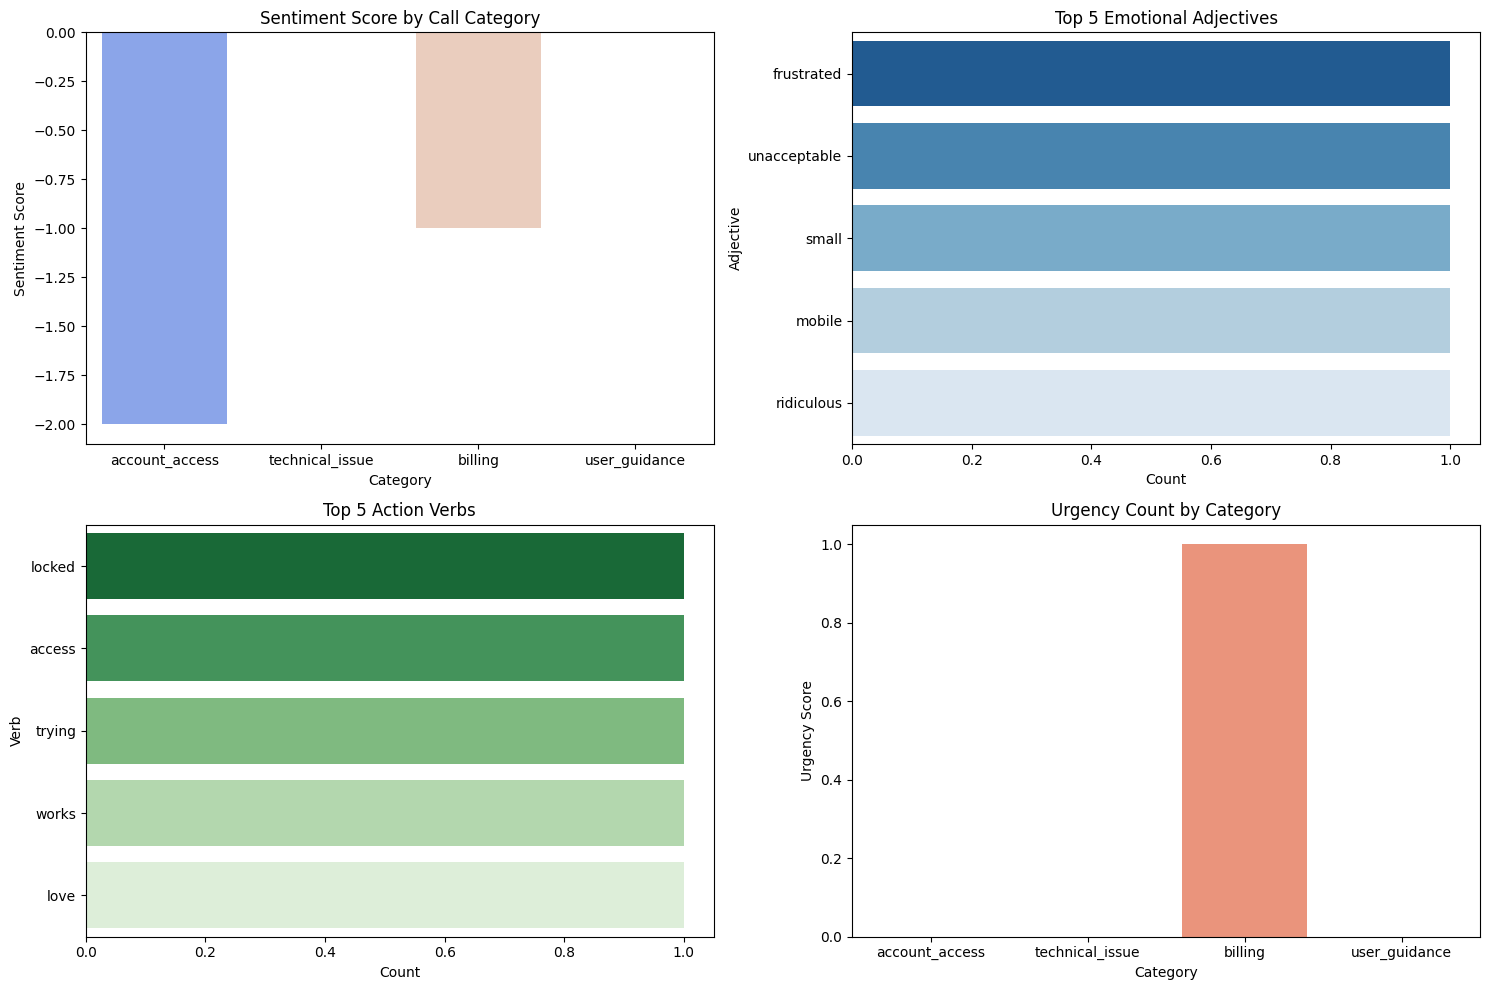

In [ ]:

# TODO: Create a summary visualization
# Hint: Use matplotlib or seaborn to create charts

import matplotlib.pyplot as plt
import pandas as pd

# Convert results to DataFrame for easier analysis
df = pd.DataFrame(analysis_results)

# TODO: Create visualizations
# 1. Sentiment scores by category
# 2. Most common emotional adjectives
# 3. Action verbs frequency

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
# 1. Plot 1 - Sentiment by category
sns.barplot(data=df, x='category', y='sentiment_score', ax=axes[0, 0], palette='coolwarm')
axes[0, 0].set_title('Sentiment Score by Call Category')
axes[0, 0].set_xlabel('Category')
axes[0, 0].set_ylabel('Sentiment Score')

# 2. Plot 2 - Most common emotional adjectives
all_adjectives = [adj.lower() for sublist in df['emotional_adjectives'] for adj in sublist]
adj_counts = Counter(all_adjectives).most_common(5)

if adj_counts:
    adj_df = pd.DataFrame(adj_counts, columns=['Adjective', 'Count'])
    sns.barplot(data=adj_df, x='Count', y='Adjective', ax=axes[0, 1], palette='Blues_r')
    axes[0, 1].set_title('Top 5 Emotional Adjectives')

# 3. Plot 3 - Action verbs frequency
all_verbs = [verb.lower() for sublist in df['action_verbs'] for verb in sublist]
verb_counts = Counter(all_verbs).most_common(5)

if verb_counts:
    verb_df = pd.DataFrame(verb_counts, columns=['Verb', 'Count'])
    sns.barplot(data=verb_df, x='Count', y='Verb', ax=axes[1, 0], palette='Greens_r')
    axes[1, 0].set_title('Top 5 Action Verbs')

# 4. Plot 4 - Urgency indicators by category
sns.barplot(data=df, x='category', y='urgency_indicators', ax=axes[1, 1], palette='Reds_r')
axes[1, 1].set_title('Urgency Count by Category')
axes[1, 1].set_xlabel('Category')
axes[1, 1].set_ylabel('Urgency Score')


plt.tight_layout()
plt.show()


### 💼 Business Impact Questions:
1. How could this analysis help prioritize customer service tickets?

The system could look for negative language and urgent words. A ticket that sounds very negative or urgent could be moved to the front of the queue.

2. What patterns do you notice in different problem categories?

Each category has its own common words. Account access calls use words such as "account," "locked," and "access." Technical calls use words such as "app" and "crashes," while billing calls use words such as "charged" and "refund."

3. How might you automate the routing of calls based on POS analysis?

The system could find important nouns and verbs and use them to send each ticket to the right team. For example, "refund" could go to billing, while "app" and "crashes" could go to technical support.

4. What are the limitations of this approach?

POS tags tell us the grammatical role of a word, but they do not always explain its meaning. The system may still misunderstand negation, sarcasm, or words that have different meanings in different situations.


## ⚡ Lab Exercise 3: Tagger Performance Benchmarking (20 minutes)

Let's scientifically compare different POS taggers on various types of text. This will help you understand when to use which tool.


⚡ TAGGER BENCHMARKING RESULTS


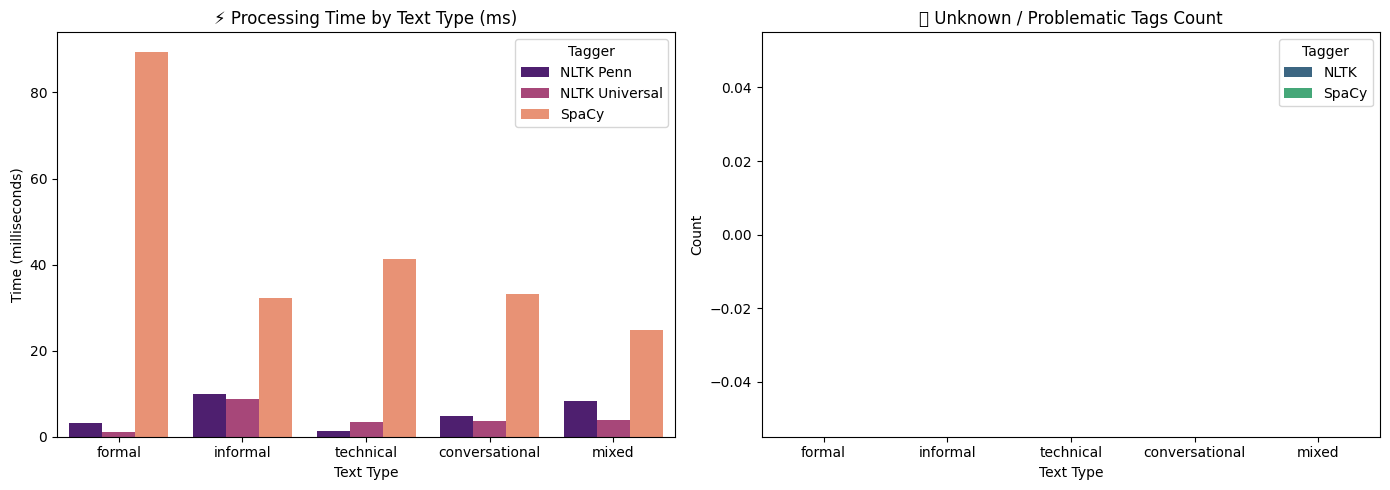

In [ ]:
import time
from collections import defaultdict

# Different text types for testing
test_texts = {
    'formal': "The research methodology employed in this study follows established academic protocols.",
    'informal': "lol this study is kinda weird but whatever works i guess 🤷",
    'technical': "The API returns a JSON response with HTTP status code 200 upon successful authentication.",
    'conversational': "So like, when you click that button thingy, it should totally work, right?",
    'mixed': "OMG the algorithm's performance is absolutely terrible! The accuracy dropped to 23%"
}

benchmark_results = []

print("⚡ TAGGER BENCHMARKING RESULTS")
print("=" * 60)

for text_type, text in test_texts.items():
    # 1. Benchmark NLTK Penn Treebank
    start_time = time.time()
    nltk_penn_tokens = nltk.word_tokenize(text)
    nltk_penn_tags = nltk.pos_tag(nltk_penn_tokens)
    penn_time = (time.time() - start_time) * 1000  # in ms

    # 2. Benchmark NLTK Universal
    start_time = time.time()
    nltk_univ_tokens = nltk.word_tokenize(text)
    nltk_univ_tags = nltk.pos_tag(nltk_univ_tokens, tagset='universal')
    univ_time = (time.time() - start_time) * 1000  # in ms

    # 3. Benchmark SpaCy
    start_time = time.time()
    spacy_doc = nlp(text)
    spacy_tags = [(token.text, token.pos_) for token in spacy_doc]
    spacy_time = (time.time() - start_time) * 1000  # in ms

    # Count unknown / problematic tags
    nltk_unknown = sum(1 for word, tag in nltk_penn_tags if tag in ['FW', 'SYM', 'X', '$'])
    spacy_unknown = sum(1 for token in spacy_doc if token.pos_ in ['X', 'SYM'])

    benchmark_results.append({
        'text_type': text_type,
        'nltk_penn_time': penn_time,
        'nltk_univ_time': univ_time,
        'spacy_time': spacy_time,
        'nltk_unknown': nltk_unknown,
        'spacy_unknown': spacy_unknown
    })

# Convert results into a DataFrame
df_benchmark = pd.DataFrame(benchmark_results)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Processing Time Comparison
df_time = df_benchmark.melt(
    id_vars=['text_type'],
    value_vars=['nltk_penn_time', 'nltk_univ_time', 'spacy_time'],
    var_name='Tagger',
    value_name='Time_ms'
)
df_time['Tagger'] = df_time['Tagger'].replace({
    'nltk_penn_time': 'NLTK Penn',
    'nltk_univ_time': 'NLTK Universal',
    'spacy_time': 'SpaCy'
})

sns.barplot(data=df_time, x='text_type', y='Time_ms', hue='Tagger', ax=axes[0], palette='magma')
axes[0].set_title('⚡ Processing Time by Text Type (ms)')
axes[0].set_xlabel('Text Type')
axes[0].set_ylabel('Time (milliseconds)')

# Plot 2: Unknown / Problematic Words Comparison
df_unknown = df_benchmark.melt(
    id_vars=['text_type'],
    value_vars=['nltk_unknown', 'spacy_unknown'],
    var_name='Tagger',
    value_name='Unknown_Count'
)
df_unknown['Tagger'] = df_unknown['Tagger'].replace({
    'nltk_unknown': 'NLTK',
    'spacy_unknown': 'SpaCy'
})

sns.barplot(data=df_unknown, x='text_type', y='Unknown_Count', hue='Tagger', ax=axes[1], palette='viridis')
axes[1].set_title('❓ Unknown / Problematic Tags Count')
axes[1].set_xlabel('Text Type')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### 📊 Performance Analysis:
1. Which tagger is fastest? Does speed matter for your use case?

In this test, NLTK was generally faster. Speed matters when an application has to process many messages or respond to users quickly. However, the result may be different on another computer.

2. Which handles informal text best?

Based on the graph, both taggers handled the informal text without producing the selected problematic tags. However, we would need correct, manually labeled tags to know which one was actually more accurate.

3. How do the taggers compare on technical jargon?

Both taggers processed the technical text without showing unknown or problematic tags. However, this does not guarantee that every technical term received the correct tag.

4. What trade-offs do you see between speed and accuracy?

The graph shows that NLTK was faster, but this experiment did not directly measure accuracy. Therefore, I can compare their speed, but I cannot tell which tagger was more accurate from this output alone.


## 🚨 Lab Exercise 4: Edge Cases and Error Analysis (15 minutes)

Every system has limitations. Let's explore the edge cases where POS taggers struggle and understand why.


In [ ]:

# Challenging edge cases
edge_cases = [
    "Buffalo buffalo Buffalo buffalo buffalo buffalo Buffalo buffalo.",  # Famous ambiguous sentence
    "Time flies like an arrow; fruit flies like a banana.",              # Classic ambiguity
    "The man the boat the river.",                                       # Garden path sentence
    "Police police Police police police police Police police.",          # Recursive structure
    "James while John had had had had had had had had had had had a better effect on the teacher.",  # Had had had...
    "Can can can can can can can can can can.",                         # Modal/noun ambiguity
    "@username #hashtag http://bit.ly/abc123 😂🔥💯",                   # Social media elements
    "COVID-19 AI/ML IoT APIs RESTful microservices",                    # Modern technical terms
]

print("🚨 EDGE CASE ANALYSIS")
print("=" * 50)

# TODO: Process each edge case and analyze failures
for i, text in enumerate(edge_cases, 1):
    print(f"\n🔍 Edge Case {i}:")
    print(f"Text: {text}")
    print("-" * 30)

    try:
        # TODO: Process with both taggers
        nltk_tags = nltk.pos_tag(nltk.word_tokenize(text))
        spacy_doc = nlp(text)


        # TODO: Identify potential errors or weird tags
        # Look for: repeated tags, unusual patterns, X tags, etc.

        print("NLTK tags:", [(w, t) for w, t in nltk_tags])
        print("SpaCy tags:", [(token.text, token.pos_) for token in spacy_doc])

        # TODO: Analyze what went wrong
        nltk_unknowns = [w for w, t in nltk_tags if t in ['FW', 'SYM', 'X', '$']]
        spacy_unknowns = [token.text for token in spacy_doc if token.pos_ in ['X', 'SYM']]

        print(f"  ⚠️ Potential issues - NLTK: {len(nltk_unknowns)} | SpaCy OOV/Unknown: {len(spacy_unknowns)}")

    except Exception as e:
        print(f"❌ Error processing: {e}")

# TODO: Reflection on limitations
print("\n🤔 REFLECTION ON LIMITATIONS:")
print("=" * 40)
print("These examples contain ambiguity, repetition, unusual grammar, and modern tokens that can make context difficult for traditional POS taggers.")


🚨 EDGE CASE ANALYSIS

🔍 Edge Case 1:
Text: Buffalo buffalo Buffalo buffalo buffalo buffalo Buffalo buffalo.
------------------------------
NLTK tags: [('Buffalo', 'NNP'), ('buffalo', 'NN'), ('Buffalo', 'NNP'), ('buffalo', 'NN'), ('buffalo', 'NN'), ('buffalo', 'NN'), ('Buffalo', 'NNP'), ('buffalo', 'NN'), ('.', '.')]
SpaCy tags: [('Buffalo', 'PROPN'), ('buffalo', 'NOUN'), ('Buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('Buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('.', 'PUNCT')]
  ⚠️ Potential issues - NLTK: 0 | SpaCy OOV/Unknown: 0

🔍 Edge Case 2:
Text: Time flies like an arrow; fruit flies like a banana.
------------------------------
NLTK tags: [('Time', 'NNP'), ('flies', 'NNS'), ('like', 'IN'), ('an', 'DT'), ('arrow', 'NN'), (';', ':'), ('fruit', 'CC'), ('flies', 'NNS'), ('like', 'IN'), ('a', 'DT'), ('banana', 'NN'), ('.', '.')]
SpaCy tags: [('Time', 'NOUN'), ('flies', 'VERB'), ('like', 'ADP'), ('an', 'DET'), ('arrow', 'NOUN'), (';', 'PUNCT'), 

### 🧠 Critical Thinking Questions:
1. Why do these edge cases break the taggers?

These examples use repeated words, unusual grammar, unclear meanings, and unfamiliar symbols. Because they are very different from normal sentences, the taggers have trouble deciding how each word is being used.

2. How might you preprocess text to handle some of these issues?

We could correct common spelling mistakes, expand slang, separate hashtags, and change emojis into words. However, we should be careful because too much cleaning may remove useful information.

3. When would these limitations matter in real applications?

They could matter in social media monitoring, chatbots, search engines, and translation. An incorrect tag may cause the system to misunderstand a sentence or a user's request.

4. How do modern large language models handle these cases differently?

Large language models look at relationships between words across the whole sentence. This gives them more context for understanding unclear words, although they can still make mistakes with very unusual sentences.
---


## 🎯 Final Reflection and Submission

Congratulations! You've completed a comprehensive exploration of POS tagging, from basic concepts to real-world challenges.

### 📝 Reflection Questions (Answer in the cell below):

1. **Tool Comparison**: Based on your experience, when would you choose NLTK vs SpaCy? Consider factors like ease of use, accuracy, speed, and application type.

2. **Real-World Applications**: Describe a specific business problem where POS tagging would be valuable. How would you implement it?

3. **Limitations and Solutions**: What are the biggest limitations you discovered? How might you work around them?

4. **Future Learning**: What aspects of POS tagging would you like to explore further? (Neural approaches, custom training, domain adaptation, etc.)

5. **Integration**: How does POS tagging fit into larger NLP pipelines? What other NLP tasks might benefit from POS information?


### ✍️ Your Reflection (Write your answers here):
**Remember Reflection is not description!**

**1. Tool Comparison:**

I would choose SpaCy for real-world applications because its tags are easy to read and it includes several useful NLP features. I would choose NLTK for learning and small experiments because it lets me see and compare different tag sets. NLTK is often lighter and faster, while SpaCy is useful for building a larger NLP project.

**2. Real-World Applications:**

One useful application is customer support ticket routing. POS tagging can help identify nouns that describe the problem and verbs that show what the customer wants. I would use SpaCy to process each ticket, find the important words, and send the ticket to the correct support team.

**3. Limitations and Solutions:**

The biggest problems I noticed were ambiguous words, slang, abbreviations, emojis, and unusual sentence structures. Careful text cleaning and training the model on similar data could help. Human review may also be needed when the system is unsure.

**4. Future Learning:**

I would like to learn more about transformer-based POS tagging. I am interested in seeing how models such as BERT compare with NLTK and SpaCy, especially when working with informal or technical text.

**5. Integration:**

POS tagging can support other NLP tasks such as named entity recognition, information extraction, and sentiment analysis. For example, nouns can point to important subjects, while adjectives can show opinions or descriptions. This grammatical information can help the rest of an NLP system understand the text better.


---

## 📤 Submission Checklist

Before submitting your completed notebook, make sure you have:

- [ ] ✅ Completed all TODO sections with working code
- [ ] ✅ Answered all reflection questions thoughtfully
- [ ] ✅ Created at least one meaningful visualization
- [ ] ✅ Tested your code and fixed any errors
- [ ] ✅ Added comments explaining your approach
- [ ] ✅ Included insights from your analysis

### 📋 Submission Instructions:
1. **Save your notebook**: File → Save (or Ctrl+S)
2. **Download**: File → Download → Download .ipynb
3. **Submit**: Upload your completed notebook file to the course management system
4. **Filename**: Use format: `L05_LastName_FirstName_ITAI2373.ipynb or pdf`  

### 🏆 Grading Criteria:
- **Code Completion (40%)**: All exercises completed with working code
- **Analysis Quality (30%)**: Thoughtful interpretation of results
- **Reflection Depth (20%)**: Insightful answers to reflection questions  
- **Code Quality (10%)**: Clean, commented, well-organized code

---

## 🎉 Great Work!

You've successfully explored the fascinating world of POS tagging! You now understand how computers parse human language and can apply these techniques to solve real-world problems.


Keep exploring and happy coding! 🚀
